## Memory for Recurrent Neural Networks




In [28]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# one-hot encoding
def encode(sequence, n_unique):
	encoded = list()
	for value in sequence:
		row = [0.0 for x in range(n_unique)]
		row[value] = 1.0
		encoded.append(row)
	return encoded

seq1 = [0, 1, 2, 3, 4, 5]
encoded = encode(seq1, 20)
for v in encoded:
	print(v)

[1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


In [29]:
# create pairs of encoded vectors, returns X, y

def train(encoded):
	X,y = list(),list()
	for i in range(2, len(encoded)):
		# let's predict the number two steps away
		X.append(encoded[i-2])  # input
		y.append(encoded[i])    # output
	return X, y

In [30]:
#seq = [3, 2, 1, 0, 4, 5, 17, 10, 20, 30, 23, 24, 6, 26, 30, 12, 14, 30, 22, 29]
seq = [3, 2, 1, 0, 4, 5, 17, 10, 20, 67, 23, 24, 6, 26, 67, 12, 14, 67, 22, 29, 1, 2, 4, 5, 6, 7, 8, 9, 8, 7,6, 42, 42, 42, 1,1, 2, 4, 5, 6, 7, 8, 9, 8, 7,6, 5, 4, 13, 12, 11, 67, 30, 65, 64 ]

encoded = encode(seq, np.array(seq).max()+1)

X, y = train(encoded)
for i in range(len(X)):
	print(X[i], y[i])

[0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0] [0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
[0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.

In [31]:
# preprocess sequences to use in LSTM

def preprocessing(sequence, n_unique):
	# onehotencoding
	encoded = encode(sequence, n_unique)
	# construct train set
	X,y = train(encoded)
	# convert and reshape for use in LSTM
	X, y = pd.DataFrame(X), pd.DataFrame(y)
	X = X.values
	X_new = X.reshape(X.shape[0], 1, X.shape[1])
	Y_new = y.values
	return X_new, Y_new

In [32]:
sequence_X, sequence_Y = preprocessing(seq, np.array(seq).max()+1)

In [33]:
sequence_X

array([[[0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 1., ..., 0., 0., 0.]],

       [[0., 1., 0., ..., 0., 0., 0.]],

       ...,

       [[0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 1.]],

       [[0., 0., 0., ..., 0., 0., 0.]]], shape=(53, 1, 68))

In [34]:
# Define PyTorch LSTM Model
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(LSTMModel, self).__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x, hidden=None):
        # x shape: (batch_size, seq_len, input_size)
        lstm_out, hidden = self.lstm(x, hidden)
        # Take only the last output
        output = self.fc(lstm_out[:, -1, :])
        output = self.sigmoid(output)
        return output, hidden

# define LSTM configuration
n_neurons = 128
n_batch = 1
n_epoch = 300
n_features = max(seq)+1

# Convert data to PyTorch tensors
X_tensor = torch.FloatTensor(sequence_X)
Y_tensor = torch.FloatTensor(sequence_Y)

print(f"Input tensor shape: {X_tensor.shape}")
print(f"Output tensor shape: {Y_tensor.shape}")

# construct a model
model = LSTMModel(input_size=n_features, hidden_size=n_neurons, output_size=n_features)
criterion = nn.BCELoss()  # Binary Cross Entropy Loss
optimizer = optim.Adam(model.parameters())

print("Model architecture:")
print(model)

Input tensor shape: torch.Size([53, 1, 68])
Output tensor shape: torch.Size([53, 68])
Model architecture:
LSTMModel(
  (lstm): LSTM(68, 128, batch_first=True)
  (fc): Linear(in_features=128, out_features=68, bias=True)
  (sigmoid): Sigmoid()
)


In [35]:
# train LSTM
model.train()
losses = []

print("Training LSTM model...")
for epoch in range(n_epoch):
    total_loss = 0
    hidden = None  # Initialize hidden state for stateful behavior

    for i in range(len(X_tensor)):
        # Get individual samples (maintaining stateful behavior)
        x_sample = X_tensor[i:i+1]  # Shape: (1, 1, n_features)
        y_sample = Y_tensor[i:i+1]  # Shape: (1, n_features)

        # Forward pass
        optimizer.zero_grad()
        output, hidden = model(x_sample, hidden)

        # Detach hidden state to prevent backpropagation through entire sequence
        if hidden is not None:
            hidden = (hidden[0].detach(), hidden[1].detach())

        # Calculate loss
        loss = criterion(output, y_sample)

        # Backward pass
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(X_tensor)
    losses.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(f'Epoch [{epoch+1}/{n_epoch}], Loss: {avg_loss:.6f}')

print("Training completed!")

Training LSTM model...
Epoch [10/300], Loss: 0.068509
Epoch [20/300], Loss: 0.063220
Epoch [30/300], Loss: 0.058995
Epoch [40/300], Loss: 0.053226
Epoch [50/300], Loss: 0.043789
Epoch [60/300], Loss: 0.033398
Epoch [70/300], Loss: 0.024334
Epoch [80/300], Loss: 0.017053
Epoch [90/300], Loss: 0.011737
Epoch [100/300], Loss: 0.008708
Epoch [110/300], Loss: 0.006454
Epoch [120/300], Loss: 0.004996
Epoch [130/300], Loss: 0.004077
Epoch [140/300], Loss: 0.003402
Epoch [150/300], Loss: 0.004792
Epoch [160/300], Loss: 0.002685
Epoch [170/300], Loss: 0.002462
Epoch [180/300], Loss: 0.002310
Epoch [190/300], Loss: 0.002189
Epoch [200/300], Loss: 0.002091
Epoch [210/300], Loss: 0.002012
Epoch [220/300], Loss: 0.001969
Epoch [230/300], Loss: 0.001903
Epoch [240/300], Loss: 0.001860
Epoch [250/300], Loss: 0.001830
Epoch [260/300], Loss: 0.001821
Epoch [270/300], Loss: 0.001809
Epoch [280/300], Loss: 0.001773
Epoch [290/300], Loss: 0.002413
Epoch [300/300], Loss: 0.001883
Training completed!


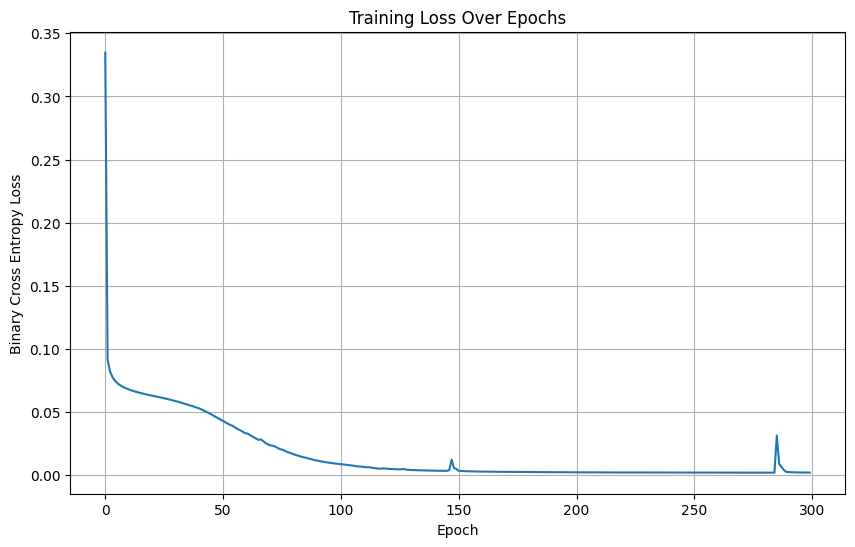

Final loss: 0.001883
Initial loss: 0.334656
Loss reduction: 99.44%


In [36]:
# Visualize training progress
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(losses)
plt.title('Training Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Binary Cross Entropy Loss')
plt.grid(True)
plt.show()

print(f"Final loss: {losses[-1]:.6f}")
print(f"Initial loss: {losses[0]:.6f}")
print(f"Loss reduction: {((losses[0] - losses[-1]) / losses[0] * 100):.2f}%")

In [37]:
# Make predictions using PyTorch model
model.eval()
predictions = []
hidden = None

with torch.no_grad():
    for i in range(len(X_tensor)):
        x_sample = X_tensor[i:i+1]
        output, hidden = model(x_sample, hidden)
        # Detach hidden state for stateful behavior
        if hidden is not None:
            hidden = (hidden[0].detach(), hidden[1].detach())
        predictions.append(output.numpy())

predictions = np.array(predictions).squeeze()
result = np.argmax(predictions, axis=-1)

# test LSTM on sequence
print('Original Sequence:')
print(seq)
print('\nPredictions vs Actual (2 steps ahead):')
for i in range(len(result)):
    actual_next = seq[i+2] if i+2 < len(seq) else "N/A"
    print(f"X = {seq[i]}, Predicted = {result[i]}, Actual = {actual_next}")

Original Sequence:
[3, 2, 1, 0, 4, 5, 17, 10, 20, 67, 23, 24, 6, 26, 67, 12, 14, 67, 22, 29, 1, 2, 4, 5, 6, 7, 8, 9, 8, 7, 6, 42, 42, 42, 1, 1, 2, 4, 5, 6, 7, 8, 9, 8, 7, 6, 5, 4, 13, 12, 11, 67, 30, 65, 64]

Predictions vs Actual (2 steps ahead):
X = 3, Predicted = 1, Actual = 1
X = 2, Predicted = 0, Actual = 0
X = 1, Predicted = 4, Actual = 4
X = 0, Predicted = 5, Actual = 5
X = 4, Predicted = 17, Actual = 17
X = 5, Predicted = 10, Actual = 10
X = 17, Predicted = 20, Actual = 20
X = 10, Predicted = 67, Actual = 67
X = 20, Predicted = 23, Actual = 23
X = 67, Predicted = 24, Actual = 24
X = 23, Predicted = 6, Actual = 6
X = 24, Predicted = 26, Actual = 26
X = 6, Predicted = 67, Actual = 67
X = 26, Predicted = 12, Actual = 12
X = 67, Predicted = 14, Actual = 14
X = 12, Predicted = 67, Actual = 67
X = 14, Predicted = 22, Actual = 22
X = 67, Predicted = 29, Actual = 29
X = 22, Predicted = 1, Actual = 1
X = 29, Predicted = 2, Actual = 2
X = 1, Predicted = 4, Actual = 4
X = 2, Predicted = 5